In [20]:
%load_ext autoreload

%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Notebook qui sert de brouillon pour le calcul du flux, du coefficient de convection $h$, etc

### À faire

Il faut estimer la puissance thermique ainsi que la consommation annuelle de carburant des systèmes suiant:

    1- Conduite avec traçage thermique, enfouie et isolée

    2- Conduite sans traçage thermique, enfouie et isolée (uniquement chauffée à la station de pompage)

    3- Conduite isolée hors-sol avec traçage thermique

    4- Conduite isolée hors-sol sans traçage thermique



In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [22]:
from utils import Weather_Data

weather_data = Weather_Data("weather_data_52038.xlsx")

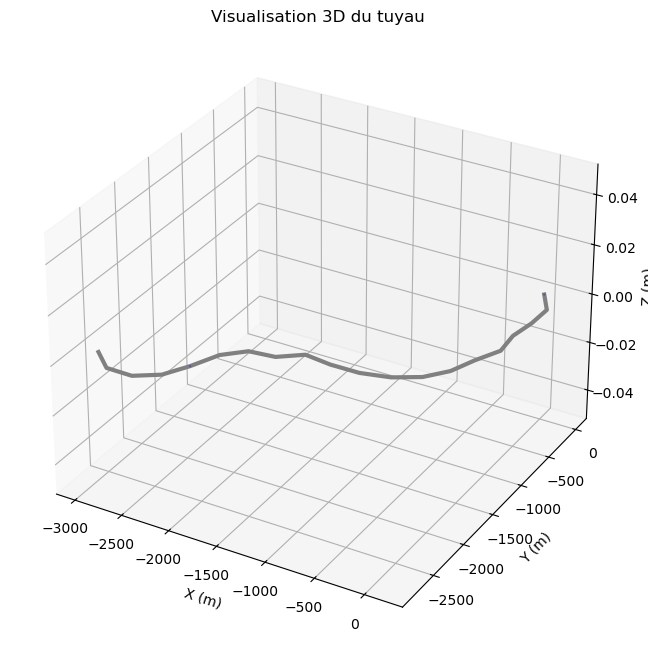

In [23]:
from utils import Pipe3D

geo = Pipe3D(0.05, 0.075)


**R_conv - Convection interne (pareil pour tous les cas probablement?)**

Calculer h_eau. On généralise les conditions sur toute la conduite et pour toute l'année.
Je prends les propriétés de l'eau à 2C (275K), tant que c'est au dessus de la température de congélation. (À corriger si jamais)

In [29]:
#1. Calcul du nombre de Reynolds
m_dot = 950 #m3/jour
D_i = 0.15 #m, pas sure de D_int, ext etc.
A = np.pi*D_i**2/4
Q = m_dot/86400 #m3/s
V = Q/A #m/s
nu = 1.5e-6 #m2/s (viscosité de l'eau à 1C, écrit dans notre texte)
ReD = V*D_i/nu
print(f'ReD = {ReD}')
print("Écoulement pleinement turbulent (ReD > 10000)")

#2. Corrélation pour NuD
Pr = 12.5 #environ
k = 0.565
NuD = 0.023*(ReD**(4/5))*Pr**0.3 #Dittus-Boelter, refroidissement
h_i = NuD*k/D_i

R_conv = 1/h_i*np.pi*D_i

print(f"Avec corrélation Dittus-Boelter : h_i = {h_i}, R_conv = {R_conv}")

ReD = 62221.068286954964
Écoulement pleinement turbulent (ReD > 10000)
Avec corrélation Dittus-Boelter : h_i = 1264.468454951926, R_conv = 0.00037267746474259415


**R_ext - Convection externe (pour les 2 cas hors sol)**

À calculer par heure, tout au long de l'année, pour un seul point et généraliser pour toute la conduite.

In [ ]:
D_iso = 0.15 #m

#Les propriétés de l'air vont changer avec la température extérieure, mais comme on évalue les propriétés à Tf = (Ts + Tinf)/2 
#et que Ts = Tinf environ, on peut peut être approximer Tf = Tinf?

def coeff_convection_ray_ext(Tf, V_air):
    #Interpolation pour les propriétés de l'air à la bonne température
    #données ia à verifier, ajouter des données pe
    T_table = np.array([-40, -20, 0, 20])
    nu_table = np.array([1.05e-5, 1.20e-5, 1.35e-5, 1.51e-5])  # m2/s
    k_table = np.array([0.0223, 0.0239, 0.0257, 0.0271])       # W/mK
    Pr_table = np.array([0.720, 0.720, 0.715, 0.710])

    nu = np.interp(Tf, T_table, nu_table)
    k = np.interp(Tf, T_table, k_table)
    Pr = np.interp(Tf, T_table, Pr_table)

    #Rayonnement
    #Sera constant??
    s = 5.67e-8 #W/m2K4
    e = 0.9 #IDK
    #Ts = Tinf environ??
    Ts = Tinf = Tf

    h_r = e*s*(Ts**2 + Tinf**2)(Ts + Tinf)

    #Convection

    #Calcul de ReD
    ReD = V_air*D_iso/nu

    #Choix de la corrélation
    if ReD*Pr >= 0.2:
        #Churchill-Bernstein
        num = 0.62 * (ReD**0.5) * (Pr**(1/3))
        den = (1.0 + (0.4 / Pr)**(2/3))**(1/4)
        bracket = (1.0 + (ReD / 282000.0)**(5/8))**(4/5)
        
        NuD = 0.3 + (num / den) * bracket
        h_c = (NuD * k) / D_iso

    else:
        h_c = 0 #Pas sure de ce qu'on fait si le vent est trop faible pour utilsier Churchill-Bernstein

    h_e = h_c + h_r

    return h_e

#Créer array avec toutes les valeurs de R_conv_ext à partir des h_e


**R_cond - Conduction dans la paroi de la conduite (Pareil pour tous les cas)**

Pour les propriétés, je crois qu'on peut les approximer constantes (T_moyen = (Ts1 + Ts2)/2 ne change pas beaucoup... et k ne change pas beaucoup sur les températures autour de 0-10C)

In [26]:
#Valeurs whatever, à changer
D_int = 0.10
D_ext = 0.125
k_cond = 50 #W/mK

R_cond = np.log(D_ext/D_int)/2*np.pi*k_cond

**R_iso - Conduction dans l'isolant (Pareil pour tous les cas)**

In [27]:
#Valeurs whatever
D_ext = 0.125
D_iso = 0.15
k_iso = 0.03 #W/mK

R_iso = np.log(D_iso/D_ext)/2*np.pi*k_iso

**R_sol - Conduction dans le sol (Pour les 2 cas enfouis)**

In [28]:
D_iso = 0.15 #m
k_sol = 2 #W/mK pour du permafrost... mais jsp a quel point on doit être précis la dessus, on garde ça constant j'imagine? une cause d'erreur
z = 2 #m, profondeur d'enfouissement, à changer
R_sol = np.arccosh(2*z/D_iso)/2*np.pi*k_sol

**Circuits thermiques pour flux**

In [ ]:

# 1- Conduite avec traçage thermique, enfouie et isolée

# 2- Conduite sans traçage thermique, enfouie et isolée (uniquement chauffée à la station de pompage)

# 3- Conduite isolée hors-sol avec traçage thermique

# 4- Conduite isolée hors-sol sans traçage thermique